DBSCN Clustring

In [2]:
import pandas as pd 
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt


In [3]:
def createDataPoints(centroidLocation, numSamples, clusterDeviation):
    X,y = make_blobs(n_samples= numSamples , centers=centroidLocation , cluster_std=clusterDeviation)

    X = StandardScaler().fit_transform(X)

    return X,y

In [4]:
X,y = createDataPoints([[4,3], [2,-1], [-1,4]] , 1500, 0.5)

In [5]:
epsilon = 0.3
minimumSamples = 7
db =DBSCAN(eps=epsilon , min_samples=minimumSamples).fit(X)
labels = db.labels_
labels

array([0, 0, 1, ..., 2, 1, 1])

In [6]:
core_samples_mask = np.zeros_like( labels , dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
core_samples_mask

array([ True,  True,  True, ...,  True,  True,  True])

In [7]:
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_clusters_

3

In [8]:
unique_labels = set(labels)
unique_labels

{np.int64(-1), np.int64(0), np.int64(1), np.int64(2)}

In [9]:
colors = plt.cm.Spectral(np.linspace(0, 1, len(unique_labels)))

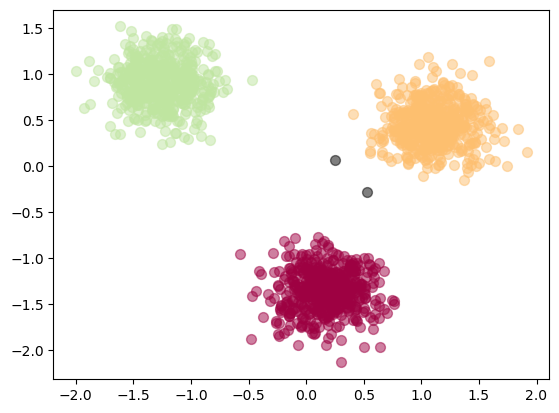

In [ ]:
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = 'Sk'

    class_member_mask = (labels == k)

    # Plot the datapoints that are clustered
    xy = X[class_member_mask & core_samples_mask]
    plt.scatter(xy[:, 0], xy[:, 1],s=50, c=[col], marker=u'o', alpha=0.5)

    # Plot the outliers
    xy = X[class_member_mask & ~core_samples_mask]
    plt.scatter(xy[:, 0], xy[:, 1],s=50, c=[col], marker=u'o', alpha=0.5)